In [30]:
# =====================================================
# CELL 1 : INSTALL REQUIRED PACKAGES
# =====================================================
!pip install pennylane torch numpy pandas matplotlib scikit-learn seaborn

In [31]:
# =====================================================
# CELL 2 : IMPORT LIBRARIES
# =====================================================
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
import pennylane as qml
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)
print("PyTorch Version :", torch.__version__)
print("PennyLane Version :", qml.__version__)

PyTorch Version : 2.15.0+cpu
PennyLane Version : 0.45.1


In [32]:
# =====================================================
# CELL 3 : REPRODUCIBILITY & ENVIRONMENT SETUP
# =====================================================
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (8,5)
print("Random Seed :", RANDOM_SEED)

Random Seed : 42


In [33]:
# =====================================================
# CELL 4 : SYNTHETIC DATASET GENERATION
# =====================================================
FEATURES = 16
NORMAL_SAMPLES = 1200
ANOMALY_SAMPLES = 150
row,col = np.indices((FEATURES,FEATURES))
toeplitz_cov = np.exp(
    -np.abs(row-col)/3.0
)
normal_mean = np.zeros(FEATURES)
X_normal = np.random.multivariate_normal(
    normal_mean,
    toeplitz_cov,
    NORMAL_SAMPLES
)
anomaly_mean = np.ones(FEATURES)*1.5
anomaly_mean[::2] += 1.0
anomaly_cov = toeplitz_cov * 1.8
X_anomaly = np.random.multivariate_normal(
    anomaly_mean,
    anomaly_cov,
    ANOMALY_SAMPLES
)
scaler = MinMaxScaler(
    feature_range=(0,np.pi)
)
X_normal_scaled = scaler.fit_transform(X_normal)
X_anomaly_scaled = np.clip(
    scaler.transform(X_anomaly),
    0,
    np.pi
)
X_train_nominal = X_normal_scaled[:800]
X_validation_nominal = X_normal_scaled[800:1000]
X_test_nominal = X_normal_scaled[1000:]
X_test_anomaly = X_anomaly_scaled
X_test = np.vstack(
    [X_test_nominal,X_test_anomaly]
)
y_test = np.array(
    [0]*len(X_test_nominal)
    +
    [1]*len(X_test_anomaly)
)
print("Training :", X_train_nominal.shape)
print("Validation :", X_validation_nominal.shape)
print("Test :", X_test.shape)

Training : (800, 16)
Validation : (200, 16)
Test : (350, 16)


In [34]:
# =====================================================
# CELL 5 : QUANTUM CIRCUIT DEFINITION
# =====================================================
NUM_QUBITS = 4
CIRCUIT_DEPTH = 2

quantum_device = qml.device(
    "default.qubit",
    wires=NUM_QUBITS
)

@qml.qnode(
    quantum_device,
    interface="torch",
    diff_method="backprop"
)
def quantum_feature_map(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(NUM_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights=weights,
        wires=range(NUM_QUBITS)
    )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(NUM_QUBITS)
    ]

WEIGHT_SHAPES = {
    "weights": (CIRCUIT_DEPTH, NUM_QUBITS, 3)
}

print("Quantum circuit created successfully.")

Quantum circuit created successfully.


In [35]:
# =====================================================
# CELL 6 : DUAL-SPACE HQCAE ARCHITECTURE
# =====================================================


class DualSpaceHQCAE(nn.Module):

    def __init__(self):

        super().__init__()

        self.feature_encoder = nn.Sequential(
            nn.Linear(16, 8),
            nn.Tanh(),

            nn.Linear(8, 4),
            nn.Sigmoid()
        )

        self.quantum_block = qml.qnn.TorchLayer(
            quantum_feature_map,
            WEIGHT_SHAPES
        )

        self.feature_decoder = nn.Sequential(
            nn.Linear(4, 8),
            nn.Tanh(),

            nn.Linear(8, 16),
            nn.Sigmoid()
        )

    def forward(self, x):

        latent_representation = (
            self.feature_encoder(x)
            * np.pi
        )

        quantum_features = (
            self.quantum_block(
                latent_representation
            )
        )

        reconstructed_output = (
            self.feature_decoder(
                quantum_features
            )
            * np.pi
        )

        return reconstructed_output


hqcae_model = DualSpaceHQCAE()

print(hqcae_model)

total_parameters = sum(
    p.numel()
    for p in hqcae_model.parameters()
)

print(
    f"\nTotal Parameters : {total_parameters}"
)

DualSpaceHQCAE(
  (feature_encoder): Sequential(
    (0): Linear(in_features=16, out_features=8, bias=True)
    (1): Tanh()
    (2): Linear(in_features=8, out_features=4, bias=True)
    (3): Sigmoid()
  )
  (quantum_block): <Quantum Torch Layer: func=quantum_feature_map>
  (feature_decoder): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): Tanh()
    (2): Linear(in_features=8, out_features=16, bias=True)
    (3): Sigmoid()
  )
)

Total Parameters : 380


In [38]:
# =====================================================
# CELL 7 : DATA LOADER CONFIGURATION
# =====================================================

from torch.utils.data import TensorDataset, DataLoader

# Training Dataset
train_dataset = TensorDataset(
    torch.tensor(
        X_train_nominal,
        dtype=torch.float32
    )
)

# Validation Dataset
validation_dataset = TensorDataset(
    torch.tensor(
        X_validation_nominal,
        dtype=torch.float32
    )
)

# Batch Size
BATCH_SIZE = 64

# Data Loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("=" * 50)
print("DATA PIPELINE SUMMARY")
print("=" * 50)

print(
    f"Training Samples     : "
    f"{len(train_dataset)}"
)

print(
    f"Validation Samples   : "
    f"{len(validation_dataset)}"
)

print(
    f"Training Batches     : "
    f"{len(train_loader)}"
)

print(
    f"Validation Batches   : "
    f"{len(validation_loader)}"
)

DATA PIPELINE SUMMARY
Training Samples     : 800
Validation Samples   : 200
Training Batches     : 13
Validation Batches   : 4


In [39]:
# =====================================================
# CELL 8 : HQCAE MODEL TRAINING
# =====================================================

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    torch.tensor(
        X_train_nominal,
        dtype=torch.float32
    )
)

validation_dataset = TensorDataset(
    torch.tensor(
        X_validation_nominal,
        dtype=torch.float32
    )
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches :", len(train_loader))
print("Validation batches :", len(validation_loader))

Training batches : 13
Validation batches : 4


In [40]:
# =====================================================
# CELL 8 : HQCAE MODEL TRAINING
# =====================================================

loss_function = nn.MSELoss()

optimizer = torch.optim.Adam(
    hqcae_model.parameters(),
    lr=0.015,
    weight_decay=1e-5
)

TOTAL_EPOCHS = 20

training_curve = []
validation_curve = []

print("=" * 60)
print("DUAL-SPACE HQCAE TRAINING")
print("=" * 60)

training_start = time.time()

for epoch in range(TOTAL_EPOCHS):

    # Training Phase
    hqcae_model.train()

    epoch_train_loss = 0

    for (features,) in train_loader:

        optimizer.zero_grad()

        reconstructed_output = hqcae_model(
            features
        )

        loss = loss_function(
            reconstructed_output,
            features
        )

        loss.backward()

        optimizer.step()

        epoch_train_loss += loss.item()

    epoch_train_loss = (
        epoch_train_loss /
        len(train_loader)
    )

    training_curve.append(
        epoch_train_loss
    )

    # Validation Phase
    hqcae_model.eval()

    epoch_validation_loss = 0

    with torch.no_grad():

        for (features,) in validation_loader:

            reconstructed_output = (
                hqcae_model(features)
            )

            validation_loss = (
                loss_function(
                    reconstructed_output,
                    features
                )
            )

            epoch_validation_loss += (
                validation_loss.item()
            )

    epoch_validation_loss = (
        epoch_validation_loss /
        len(validation_loader)
    )

    validation_curve.append(
        epoch_validation_loss
    )

    print(
        f"Epoch {epoch+1:02d}/{TOTAL_EPOCHS}"
        f" | Train MSE = {epoch_train_loss:.5f}"
        f" | Validation MSE = {epoch_validation_loss:.5f}"
    )

training_time = (
    time.time() -
    training_start
)

print("\nTraining Complete ✅")

print(
    f"Execution Time : "
    f"{training_time:.2f} seconds"
)

DUAL-SPACE HQCAE TRAINING
Epoch 01/20 | Train MSE = 0.24217 | Validation MSE = 0.23995
Epoch 02/20 | Train MSE = 0.21734 | Validation MSE = 0.21884
Epoch 03/20 | Train MSE = 0.19118 | Validation MSE = 0.20177
Epoch 04/20 | Train MSE = 0.17411 | Validation MSE = 0.18568
Epoch 05/20 | Train MSE = 0.16191 | Validation MSE = 0.17688
Epoch 06/20 | Train MSE = 0.15651 | Validation MSE = 0.17430
Epoch 07/20 | Train MSE = 0.15507 | Validation MSE = 0.16937
Epoch 08/20 | Train MSE = 0.15430 | Validation MSE = 0.16747
Epoch 09/20 | Train MSE = 0.15004 | Validation MSE = 0.16704
Epoch 10/20 | Train MSE = 0.14083 | Validation MSE = 0.14725
Epoch 11/20 | Train MSE = 0.12634 | Validation MSE = 0.13141
Epoch 12/20 | Train MSE = 0.11718 | Validation MSE = 0.12637
Epoch 13/20 | Train MSE = 0.11240 | Validation MSE = 0.12253
Epoch 14/20 | Train MSE = 0.11043 | Validation MSE = 0.12248
Epoch 15/20 | Train MSE = 0.11046 | Validation MSE = 0.11908
Epoch 16/20 | Train MSE = 0.10912 | Validation MSE = 0.1185

In [41]:
# =====================================================
# CELL 9 : CLASSICAL RECONSTRUCTION ANALYSIS
# =====================================================

hqcae_model.eval()

test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

with torch.no_grad():

    reconstructed_samples = (
        hqcae_model(
            test_tensor
        ).numpy()
    )

# Mean Squared Reconstruction Error
reconstruction_error = np.mean(
    (X_test - reconstructed_samples) ** 2,
    axis=1
)

# ROC-AUC
roc_auc_classical = roc_auc_score(
    y_test,
    reconstruction_error
)

fpr_classical, tpr_classical, threshold_values = roc_curve(
    y_test,
    reconstruction_error
)

# Youden's J Statistic
youden_j = (
    tpr_classical -
    fpr_classical
)

best_threshold_index = np.argmax(
    youden_j
)

threshold_classical = (
    threshold_values[
        best_threshold_index
    ]
)

predicted_classical = (
    reconstruction_error >= threshold_classical
).astype(int)

confusion_matrix_classical = confusion_matrix(
    y_test,
    predicted_classical
)

classical_report = classification_report(
    y_test,
    predicted_classical,
    output_dict=True
)

print("=" * 60)
print("CLASSICAL RECONSTRUCTION ANALYSIS")
print("=" * 60)

print(
    f"ROC-AUC Score: "
    f"{roc_auc_classical:.4f}"
)

print(
    f"Threshold: "
    f"{threshold_classical:.5f}"
)

print(
    f"Accuracy: "
    f"{classical_report['accuracy']*100:.2f}%"
)

print("\nConfusion Matrix:")
print(confusion_matrix_classical)

CLASSICAL RECONSTRUCTION ANALYSIS
ROC-AUC Score: 0.9786
Threshold: 0.21217
Accuracy: 92.57%

Confusion Matrix:
[[186  14]
 [ 12 138]]


In [42]:
# =====================================================
# CELL 10 : QUANTUM ENTANGLEMENT ANALYSIS
# =====================================================

@qml.qnode(quantum_device)
def entropy_probe(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(NUM_QUBITS),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(NUM_QUBITS)
    )

    return qml.vn_entropy(
        wires=[0,1]
    )

print("Generating latent representations...")

with torch.no_grad():

    latent_vectors = (
        hqcae_model.feature_encoder(
            test_tensor
        ) * np.pi
    ).numpy()

trained_quantum_weights = (
    hqcae_model.quantum_block.weights
    .detach()
    .numpy()
)

print("Computing Entanglement Entropy...")

entanglement_entropy = np.array([
    entropy_probe(
        latent_vectors[i],
        trained_quantum_weights
    )
    for i in range(len(latent_vectors))
])

normal_entropy = (
    entanglement_entropy[
        y_test == 0
    ]
)

anomaly_entropy = (
    entanglement_entropy[
        y_test == 1
    ]
)

print("\n============== ENTROPY REPORT ==============")

print(
    f"Normal Mean Entropy  : "
    f"{normal_entropy.mean():.4f}"
)

print(
    f"Normal Std Entropy   : "
    f"{normal_entropy.std():.4f}"
)

print(
    f"Anomaly Mean Entropy : "
    f"{anomaly_entropy.mean():.4f}"
)

print(
    f"Anomaly Std Entropy  : "
    f"{anomaly_entropy.std():.4f}"
)

Generating latent representations...
Computing Entanglement Entropy...

============== ENTROPY REPORT ==============
Normal Mean Entropy  : 0.9938
Normal Std Entropy   : 0.0198
Anomaly Mean Entropy : 0.9660
Anomaly Std Entropy  : 0.0221


In [44]:
# =====================================================
# CELL 11 : DUAL SPACE SCORING
# =====================================================

ALPHA = 0.15

hybrid_anomaly_score = (
    reconstruction_error
    +
    ALPHA * entanglement_entropy
)

roc_auc_hybrid = roc_auc_score(
    y_test,
    hybrid_anomaly_score
)

fpr_hybrid, tpr_hybrid, threshold_hybrid = roc_curve(
    y_test,
    hybrid_anomaly_score
)

hybrid_j = (
    tpr_hybrid -
    fpr_hybrid
)

best_hybrid_idx = np.argmax(
    hybrid_j
)

optimal_hybrid_threshold = (
    threshold_hybrid[
        best_hybrid_idx
    ]
)

hybrid_predictions = (
    hybrid_anomaly_score
    >=
    optimal_hybrid_threshold
).astype(int)

hybrid_confusion = confusion_matrix(
    y_test,
    hybrid_predictions
)

hybrid_report = classification_report(
    y_test,
    hybrid_predictions,
    output_dict=True
)

print("="*60)
print("DUAL-SPACE HQCAE RESULTS")
print("="*60)

print(
    f"ROC-AUC : "
    f"{roc_auc_hybrid:.4f}"
)

print(
    f"Threshold : "
    f"{optimal_hybrid_threshold:.5f}"
)

print(
    f"Accuracy : "
    f"{hybrid_report['accuracy']*100:.2f}%"
)

print("\nConfusion Matrix")
print(hybrid_confusion)

DUAL-SPACE HQCAE RESULTS
ROC-AUC : 0.9771
Threshold : 0.36153
Accuracy : 92.57%

Confusion Matrix
[[187  13]
 [ 13 137]]


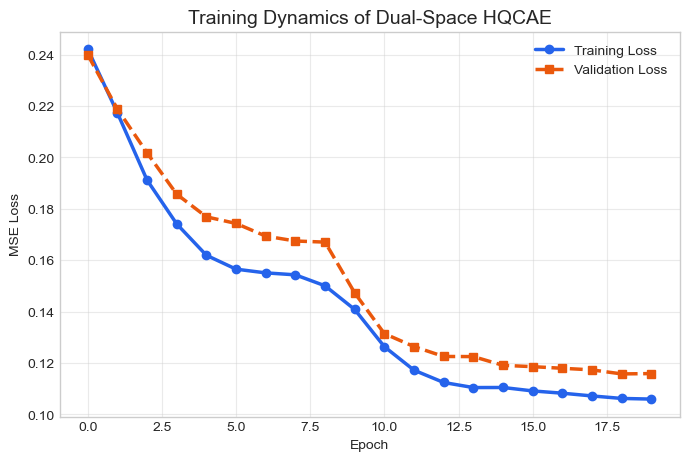

In [45]:
# =====================================================
# CELL 12 : TRAINING CONVERGENCE VISUALIZATION
# =====================================================
plt.figure(figsize=(8,5))

plt.plot(
    training_curve,
    marker="o",
    linewidth=2.5,
    color="#2563EB",
    label="Training Loss"
)

plt.plot(
    validation_curve,
    marker="s",
    linewidth=2.5,
    linestyle="--",
    color="#EA580C",
    label="Validation Loss"
)

plt.title(
    "Training Dynamics of Dual-Space HQCAE",
    fontsize=14
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()

plt.grid(alpha=0.4)

plt.show()


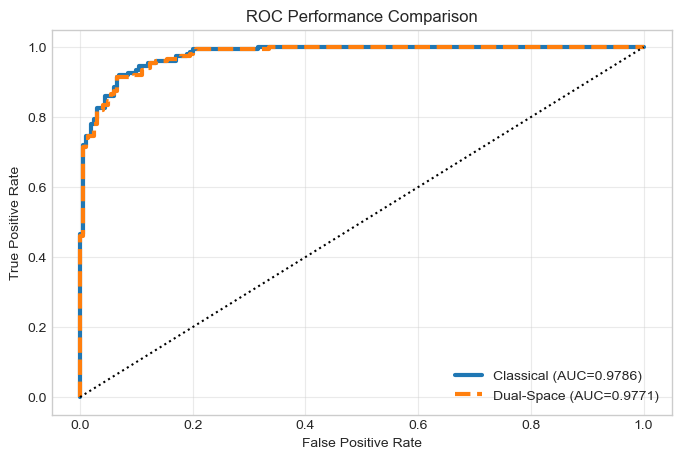

In [46]:
# =====================================================
# CELL 13 : ROC-AUC PERFORMANCE COMPARISON
# =====================================================
plt.figure(figsize=(8,5))

plt.plot(
    fpr_classical,
    tpr_classical,
    linewidth=3,
    label=f"Classical (AUC={roc_auc_classical:.4f})"
)

plt.plot(
    fpr_hybrid,
    tpr_hybrid,
    linewidth=3,
    linestyle="--",
    label=f"Dual-Space (AUC={roc_auc_hybrid:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    "k:"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Performance Comparison"
)

plt.legend()

plt.grid(alpha=0.4)

plt.show()

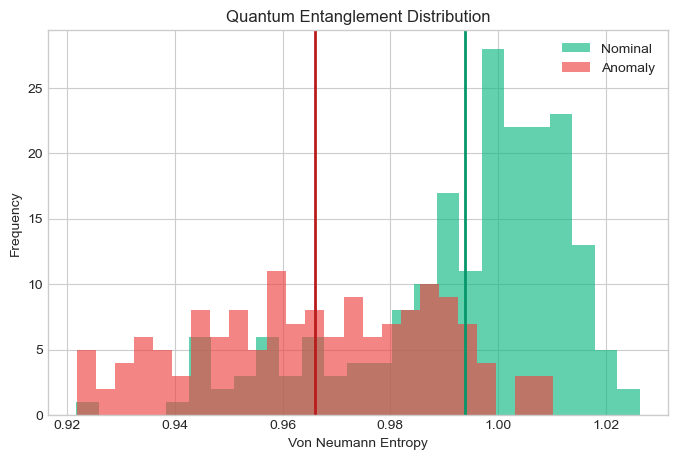

In [47]:
# =====================================================
# CELL 14 : ENTANGLEMENT ENTROPY DISTRIBUTION
# =====================================================
plt.figure(figsize=(8,5))

plt.hist(
    normal_entropy,
    bins=25,
    alpha=0.65,
    color="#10B981",
    label="Nominal"
)

plt.hist(
    anomaly_entropy,
    bins=25,
    alpha=0.65,
    color="#EF4444",
    label="Anomaly"
)

plt.axvline(
    normal_entropy.mean(),
    color="#059669",
    linewidth=2
)

plt.axvline(
    anomaly_entropy.mean(),
    color="#B91C1C",
    linewidth=2
)

plt.xlabel("Von Neumann Entropy")
plt.ylabel("Frequency")

plt.title(
    "Quantum Entanglement Distribution"
)

plt.legend()

plt.show()

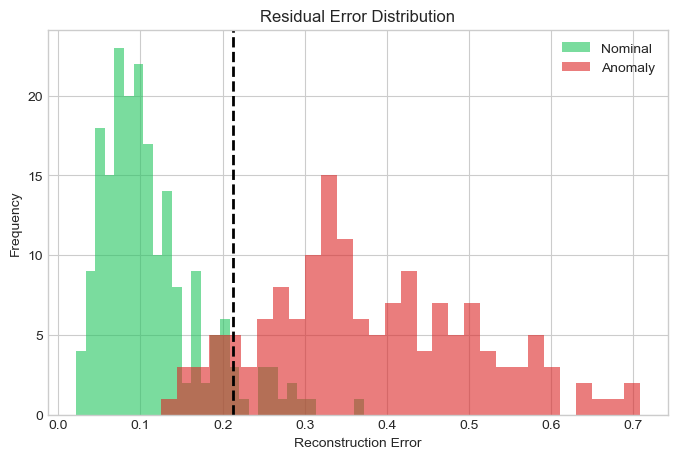

In [48]:
# =====================================================
# CELL 15 : RECONSTRUCTION ERROR DISTRIBUTION
# =====================================================
plt.figure(figsize=(8,5))

plt.hist(
    reconstruction_error[y_test==0],
    alpha=0.6,
    bins=30,
    color="#22C55E",
    label="Nominal"
)

plt.hist(
    reconstruction_error[y_test==1],
    alpha=0.6,
    bins=30,
    color="#DC2626",
    label="Anomaly"
)

plt.axvline(
    threshold_classical,
    color="black",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")

plt.title(
    "Residual Error Distribution"
)

plt.legend()

plt.show()


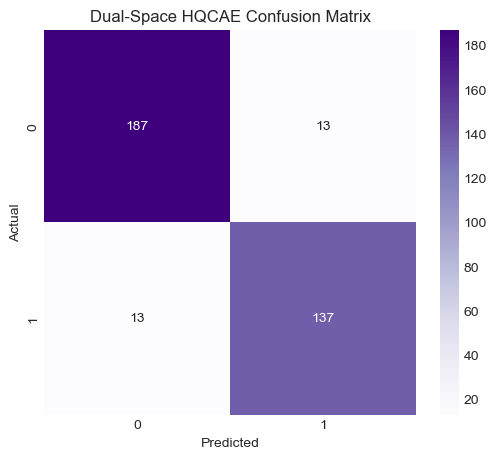

In [49]:
# =====================================================
# CELL 16 : CONFUSION MATRIX VISUALIZATION
# =====================================================
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    hybrid_confusion,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title(
    "Dual-Space HQCAE Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [50]:
# =====================================================
# CELL 17 : BENCHMARK SUMMARY TABLE
# =====================================================
summary = pd.DataFrame({

    "Metric":[
        "ROC-AUC",
        "Accuracy",
        "TN",
        "FP",
        "FN",
        "TP"
    ],

    "Classical":[
        roc_auc_classical,
        classical_report["accuracy"],
        confusion_matrix_classical[0,0],
        confusion_matrix_classical[0,1],
        confusion_matrix_classical[1,0],
        confusion_matrix_classical[1,1]
    ],

    "DualSpace":[
        roc_auc_hybrid,
        hybrid_report["accuracy"],
        hybrid_confusion[0,0],
        hybrid_confusion[0,1],
        hybrid_confusion[1,0],
        hybrid_confusion[1,1]
    ]
})

summary

,Metric,Classical,DualSpace
0,ROC-AUC,0.978567,0.977133
1,Accuracy,0.925714,0.925714
2,TN,186.000000,187.000000
3,FP,14.000000,13.000000
4,FN,12.000000,13.000000
5,TP,138.000000,137.000000
